## `meshlab` tutorial

Generate a boundary-layer mesh around L-shaped objects.

### 1. Import packages
---

In [1]:
import numpy as np

from copy import deepcopy

from meshlab.data import Mesh, Contour
from meshlab.operations import insert_contour, compute_normals, advance_front, compute_angles, smooth_normals
from meshlab.visualization import plot_mesh

from functions.create_polygon import create_polygon

### 2. Define parameters
---

In [2]:
num_layers = 3                # Number of layers
height = 0.05                 # First layer height
growth_rate = 1.10            # Ratio between two consecutive layers
points_per_edge = 5           # Number of points per edge

### 3. Geometry definition
---

In [3]:
# Define vértices
vertices = np.array([
        [  0, 0],
        [  0, 1],
        [-.5, 1],
        [-.5,-1],
        [  1,-1],
        [  1, 0],
])

# Create points
points = create_polygon(
    vertices,
    points_per_edge=[points_per_edge] * len(vertices),
)

### 4. Create boudary layer mesh
---

#### 4.1. Exemplo 1
- Sem correção da altura e normais calculadas pelo método "central".

Initialize mesh, surface and front

In [4]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Create the first layer from the circle

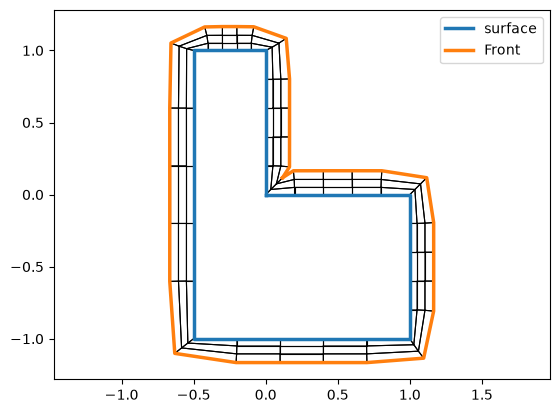

In [5]:
h = height
for _ in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front)

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, h)

    # Update height
    h *= growth_rate

# Visualize the mesh
plot_mesh(mesh, [surface, front])

#### 4.2. Exemplo 2
- Com correção da altura e normais calculadas pelo método "biscect".

Initialize mesh, surface and front

In [6]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Create the first layer from the circle

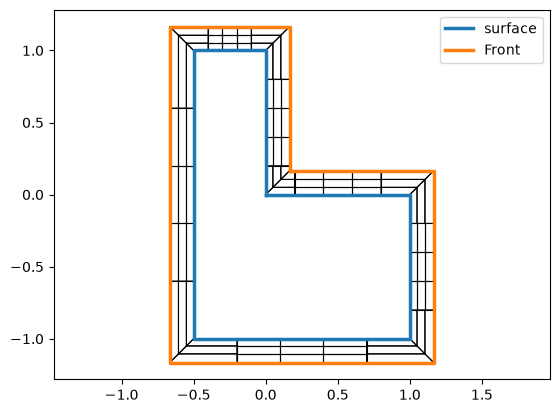

In [7]:
h = height
for _ in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front, method="bisector")

    # Compute angles and correct height
    angles = compute_angles(mesh, front)
    array = h / np.sin(angles / 2)

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, array)

    # Update height
    h *= growth_rate

# Visualize the mesh
plot_mesh(mesh, [surface, front])

#### 4.3. Exemplo 3
- Com correção da altura, normais calculadas pelo método "biscect" e com suavização de normais.
- Esse exemplo utiliza um número de camadas maior.

Initialize mesh, surface and front

In [8]:
# Initialize mesh and surfaces
mesh = Mesh()
surface = Contour("surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surfaces
front = deepcopy(surface)
front.name = "Front"

Create the first layer from the circle

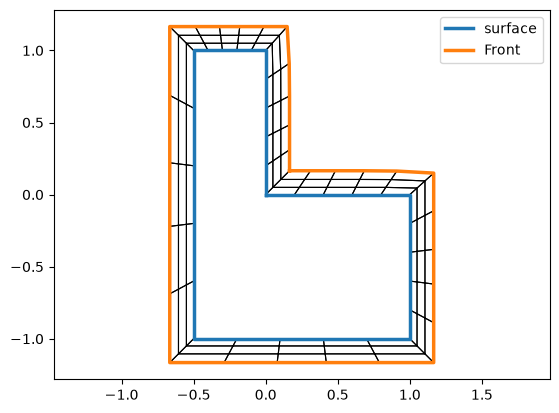

In [9]:
h = height
for i in range(num_layers):
    # Compute the front normals
    normals = compute_normals(mesh, front, method="bisector")

    # Smooth normals
    rotation = np.zeros_like(normals[:, 0])
    for _ in range(5):
        normals, r = smooth_normals(normals, 1.0)
        rotation = rotation + r

    # Compute angles and correct height
    angles = compute_angles(mesh, front)
    array = h / np.sin(angles / 2 + np.abs(rotation))

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, array)

    # Update height
    h *= growth_rate

# Visualize the mesh
plot_mesh(mesh, [surface, front])